# Axe 1 — Régression ridge (fonction quadratique)

Projet sujet C — prévision probabiliste de l'énergie solaire.

Problème traité :
$$f(w) = \frac{1}{2n}\|Aw - y\|^2 + \frac{\lambda}{2}\|w\|^2, \qquad \lambda = 10^{-2}$$

Règles suivies :
- les algorithmes (descente à pas fixe, pas exact, Armijo, Wolfe, gradient conjugué) sont écrits à la main en NumPy ;
  scikit-learn ne sert qu'à la comparaison ;
- la ligne du jour $t$ ne contient que des variables connues le jour $t$ ; la cible est $Y_t = \mathrm{ALLSKY}(t+1)$ ;
- le découpage apprentissage / test se fait sur la date de la **cible** ;
- centrage, standardisation et imputation n'utilisent que l'apprentissage ;
- les prédictions théoriques sont calculées **avant** les essais de descente (section « Prédictions »).

Le notebook télécharge les données NASA POWER automatiquement (aucun compte requis) et met le cache dans `donnees/`.

## Question et hypothèse (écrites avant les expériences)

**Question** : la descente à pas fixe $1/L$ suit-elle la vitesse théorique ? Quel gain apportent le pas exact,
la méthode d'Armijo / Wolfe, le gradient conjugué et un reconditionnement diagonal ?

**Hypothèse H1** : les colonnes de rayonnement retardé sont très corrélées ; avec $\lambda = 10^{-2}$, le conditionnement
$\kappa = L/\mu$ est donc grand. La descente à pas fixe demande alors des milliers d'itérations pour diviser
l'écart $f(w_k)-f^\star$ par $10^6$, et le gradient conjugué est nettement plus rapide.

**Hypothèse H2** : le reconditionnement diagonal gagne peu, car les variables sont déjà standardisées
(la diagonale de $H$ est à peu près constante).

In [1]:
import os
import math
import time

import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt

# ---------------------------------------------------------------- paramètres imposés
LAM = 1e-2                       # paramètre de régularisation imposé
EPS_STOP = 1e-6                  # arrêt : ||grad f(w_k)||^2 <= 1e-6 (ou MAX_ITER)
MAX_ITER = 5000                  # plafond imposé par le cahier
STUDY_ITER = 20000               # plafond pour mesurer une vitesse (sans arrêt anticipé)
RATIO_TARGET = 1e-6              # objectif : f(w_k) - f* <= 1e-6 (f(w_0) - f*)
TRAIN_END = pd.Timestamp("2023-12-31")   # dernière date de CIBLE d'apprentissage
TEST_START = pd.Timestamp("2024-01-01")  # première date de CIBLE de test
START, END = "20140101", "20260630"
PARAMS = ("ALLSKY_SFC_SW_DWN,CLRSKY_SFC_SW_DWN,T2M,T2M_MAX,T2M_MIN,"
          "RH2M,WS2M,PS,PRECTOTCORR,CLOUD_AMT")
FEATS = ["T2M", "T2M_MAX", "T2M_MIN", "RH2M", "WS2M", "PS", "PRECTOTCORR", "CLOUD_AMT"]
N_LAGS = 3                       # rayonnement des jours t, t-1, t-2 (voir section Données)
DATA_DIR = "donnees"

# Sites : trois zones climatiques contrastées (méditerranéen, désertique, sahélo-côtier).
# Le site de référence est Monastir ; le choix complet des sites (D.1 à D.3) est traité ailleurs.
SITES = {
    "Monastir": (35.78, 10.83),
    "Tamanrasset": (22.79, 5.52),
    "Dakar": (14.69, -17.44),
}
REF_SITE = "Monastir"

np.set_printoptions(precision=4, suppress=True)
pd.set_option("display.width", 120)

## 1. Données : téléchargement, contrôle des dates et unités

In [2]:
def load_site(name, lat, lon):
    """Télécharge (si absent du cache) puis charge la série journalière d'un site."""
    path = os.path.join(DATA_DIR, f"{name}.csv")
    if not os.path.exists(path):
        os.makedirs(DATA_DIR, exist_ok=True)
        url = (f"https://power.larc.nasa.gov/api/temporal/daily/point?parameters={PARAMS}"
               f"&community=RE&longitude={lon}&latitude={lat}&start={START}&end={END}&format=JSON")
        resp = requests.get(url, timeout=300)
        resp.raise_for_status()
        param = resp.json()["properties"]["parameter"]
        raw = pd.DataFrame({k: pd.Series(v) for k, v in param.items()})
        raw.index = pd.to_datetime(raw.index, format="%Y%m%d")
        raw.index.name = "date"
        raw.reset_index().to_csv(path, index=False)

    df = pd.read_csv(path, parse_dates=["date"]).set_index("date")
    df = df.replace(-999.0, np.nan)        # code NASA POWER des valeurs manquantes
    n_dup = int(df.index.duplicated().sum())
    df = df[~df.index.duplicated()]
    full = pd.date_range(df.index.min(), df.index.max(), freq="D")
    n_gap_days = len(full) - len(df)
    df = df.reindex(full)
    df.index.name = "date"
    report = {
        "site": name,
        "debut": df.index.min().date(),
        "fin": df.index.max().date(),
        "jours": len(df),
        "dates_manquantes": n_gap_days,
        "doublons": n_dup,
    }
    return df, report


def check_units(df):
    """Contrôle d'unités : ALLSKY en kWh/m2/jour, borne ciel clair >= rayonnement réel la plupart du temps."""
    a = df["ALLSKY_SFC_SW_DWN"]
    c = df["CLRSKY_SFC_SW_DWN"]
    return {
        "ALLSKY_min": round(float(a.min()), 2),
        "ALLSKY_max": round(float(a.max()), 2),
        "ALLSKY_moyenne": round(float(a.mean()), 2),
        "part_jours_ALLSKY>CLRSKY": round(float((a > c + 1e-6).mean()), 4),
        "valeurs_manquantes_par_colonne": df.isna().sum()[df.isna().sum() > 0].to_dict(),
    }


ref_df, ref_report = load_site(REF_SITE, *SITES[REF_SITE])
print(ref_report)
print(check_units(ref_df))

{'site': 'Monastir', 'debut': datetime.date(2014, 1, 1), 'fin': datetime.date(2026, 6, 30), 'jours': 4564, 'dates_manquantes': 0, 'doublons': 0}
{'ALLSKY_min': 0.52, 'ALLSKY_max': 8.81, 'ALLSKY_moyenne': 5.16, 'part_jours_ALLSKY>CLRSKY': 0.0, 'valeurs_manquantes_par_colonne': {}}


## 2. Construction des variables et découpage

- **Entrées du jour $t$** : météo du jour, trois valeurs passées de rayonnement ($t$, $t-1$, $t-2$), saisonnalité
  (sinus et cosinus de l'économie annuelle). Trois jours de mémoire : l'autocorrélation du rayonnement décroît
  vite ; au-delà, l'ajout coûte des colonnes sans gain prévu.
- **Cible** : $Y_t = \mathrm{ALLSKY}(t+1)$. $\mathrm{CLRSKY}$ n'est **jamais** une entrée.
- **Valeurs manquantes** : propagation vers l'avant seulement (aucune information du futur).
- **Découpage** : sur la date de la cible. La ligne du 31/12/2023 (entrées connues ce jour-là) prévoit le 01/01/2024 : test.
- **Standardisation et centrage** : statistiques de l'apprentissage uniquement ; colonne de 1 ajoutée à la fin.

In [3]:
def build_dataset(df):
    df = df.copy()
    cols = FEATS + ["ALLSKY_SFC_SW_DWN"]
    df[cols] = df[cols].ffill()                      # causal : seulement des valeurs passées

    X = df[FEATS].copy()
    for lag in range(N_LAGS):
        X[f"ALLSKY_lag{lag}"] = df["ALLSKY_SFC_SW_DWN"].shift(lag)
    doy = df.index.day_of_year.values
    X["sin_doy"] = np.sin(2 * np.pi * doy / 365.25)
    X["cos_doy"] = np.cos(2 * np.pi * doy / 365.25)
    X["target"] = df["ALLSKY_SFC_SW_DWN"].shift(-1)  # ALLSKY(t+1)
    X["target_date"] = df.index.to_series().shift(-1)
    data = X.dropna()

    feat_cols = [c for c in X.columns if c not in ("target", "target_date")]
    train = data[data["target_date"] <= TRAIN_END]
    test = data[data["target_date"] >= TEST_START]

    mu_x = train[feat_cols].mean()
    sd_x = train[feat_cols].std(ddof=0)
    assert (sd_x > 0).all(), "colonne constante dans l'apprentissage"
    mu_y = train["target"].mean()

    def design(d):
        Z = ((d[feat_cols] - mu_x) / sd_x).to_numpy()
        return np.column_stack([Z, np.ones(len(d))])

    return {
        "A_tr": design(train),
        "y_tr": train["target"].to_numpy() - mu_y,      # cible centrée
        "A_te": design(test),
        "y_te": test["target"].to_numpy(),
        "naive_te": test["ALLSKY_lag0"].to_numpy(),      # « demain = aujourd'hui »
        "mu_y": mu_y,
        "names": feat_cols + ["intercept"],
        "n_train": len(train),
        "n_test": len(test),
        "last_train_target": train["target_date"].max().date(),
        "first_test_target": test["target_date"].min().date(),
    }


ds = build_dataset(ref_df)
print({k: v for k, v in ds.items() if k in ("n_train", "n_test", "last_train_target", "first_test_target")})
print("dimension d =", ds["A_tr"].shape[1], "; colonnes :", ds["names"])

{'n_train': 3649, 'n_test': 912, 'last_train_target': datetime.date(2023, 12, 31), 'first_test_target': datetime.date(2024, 1, 1)}
dimension d = 14 ; colonnes : ['T2M', 'T2M_MAX', 'T2M_MIN', 'RH2M', 'WS2M', 'PS', 'PRECTOTCORR', 'CLOUD_AMT', 'ALLSKY_lag0', 'ALLSKY_lag1', 'ALLSKY_lag2', 'sin_doy', 'cos_doy', 'intercept']


## 3. Problème, gradient, hessienne, constantes $\mu$, $L$, $\kappa$

$$\nabla f(w) = \tfrac{1}{n}A^\top(Aw-y) + \lambda w, \qquad H = \tfrac{1}{n}A^\top A + \lambda I$$

$\mu = \lambda_{\min}(H)$ (forte convexité), $L = \lambda_{\max}(H)$ (gradient $L$-lipschitzien), $\kappa = L/\mu$.
Pour $\lambda = 0$, $\mu$ est la plus petite valeur propre de $A^\top A / n$ ; elle est strictement positive ici car $A$ est de rang plein.
La solution $w^\star = H^{-1}A^\top y / n$ existe et est unique ; elle sert de référence pour $f^\star$.

In [4]:
def make_problem(A, y, lam):
    n, d = A.shape

    def f(w):
        r = A @ w - y
        return r @ r / (2 * n) + 0.5 * lam * (w @ w)

    def grad(w):
        return A.T @ (A @ w - y) / n + lam * w

    def hess_vec(v):
        return A.T @ (A @ v) / n + lam * v

    H = A.T @ A / n + lam * np.eye(d)
    eig = np.linalg.eigvalsh(H)
    mu, L = float(eig[0]), float(eig[-1])
    w_star = np.linalg.solve(H, A.T @ y / n)
    return {
        "n": n, "d": d, "lam": lam, "f": f, "grad": grad, "hess_vec": hess_vec,
        "H": H, "mu": mu, "L": L, "kappa": L / mu,
        "w_star": w_star, "f_star": f(w_star),
    }


prob = make_problem(ds["A_tr"], ds["y_tr"], LAM)
rows = []
for lam in [0.0, 1e-3, 1e-2, 1e-1]:
    p = make_problem(ds["A_tr"], ds["y_tr"], lam)
    rows.append({"lambda": lam, "mu": p["mu"], "L": p["L"], "kappa": p["kappa"]})
theory_table = pd.DataFrame(rows)
print(theory_table.to_string(index=False, float_format=lambda x: f"{x:.4g}"))

 lambda       mu     L  kappa
      0 0.001344 6.392   4755
  0.001 0.002344 6.393   2727
   0.01  0.01134 6.402  564.3
    0.1   0.1013 6.492  64.06


## 4. Prédictions théoriques (calculées avant tout essai de descente)

- **Pas fixe $1/L$** : le facteur de contraction de $w_k - w^\star$ vaut $1-\mu/L = 1-1/\kappa$.
  Comme $f - f^\star$ est quadratique en l'erreur, $f(w_k)-f^\star \le (1-1/\kappa)^{2k}\,(f(w_0)-f^\star)$.
  Le nombre d'itérations pour diviser par $10^6$ est donc $k \approx \ln(10^6) / (-2\ln(1-1/\kappa)) \approx 6{,}9\,\kappa$.
- **Pas $2/(L+\mu)$** (optimal à pas fixe) : facteur $\rho = (\kappa-1)/(\kappa+1)$, donc $k \approx 3{,}5\,\kappa$.
- **Pas exact** : sur une quadratique, la borne de Kantorovich donne le même facteur que le pas $2/(L+\mu)$ ; on prédit donc
  le même ordre de grandeur.
- **Gradient conjugué** : $\|e_k\|_H \le 2\big(\tfrac{\sqrt\kappa-1}{\sqrt\kappa+1}\big)^k\|e_0\|_H$, donc
  $k \approx \ln(2\cdot 10^3)\,/\,(-\ln\tfrac{\sqrt\kappa-1}{\sqrt\kappa+1}) \approx 3{,}8\sqrt\kappa$.

Ces formules sont des **bornes au pire cas** : l'observé doit être inférieur ou égal à la prédiction.

In [5]:
def predicted_iterations(kappa):
    s = math.sqrt(kappa)
    return {
        "fixe_1/L": math.log(1 / RATIO_TARGET) / (-2 * math.log(1 - 1 / kappa)),
        "fixe_2/(L+mu)": math.log(1 / RATIO_TARGET) / (-2 * math.log((kappa - 1) / (kappa + 1))),
        "gradient_conjugue": math.log(2 / math.sqrt(RATIO_TARGET)) / (-math.log((s - 1) / (s + 1))),
    }


pred = predicted_iterations(prob["kappa"])
print(f"Site de référence {REF_SITE}, lambda = {LAM}")
print(f"  kappa = {prob['kappa']:.4g}")
for k_, v in pred.items():
    print(f"  itérations prédites ({k_}) pour diviser f - f* par 1e6 : {math.ceil(v)}")
print(f"  plafond d'étude = {STUDY_ITER}, plafond imposé = {MAX_ITER}")

Site de référence Monastir, lambda = 0.01
  kappa = 564.3
  itérations prédites (fixe_1/L) pour diviser f - f* par 1e6 : 3895
  itérations prédites (fixe_2/(L+mu)) pour diviser f - f* par 1e6 : 1950
  itérations prédites (gradient_conjugue) pour diviser f - f* par 1e6 : 91
  plafond d'étude = 20000, plafond imposé = 5000


## 5. Algorithmes (écrits à la main)

Descente générique : $w_{k+1} = w_k - \alpha_k M^{-1}\nabla f(w_k)$, avec $M = I$ (sans préconditionnement) ou $M$ = diagonale de $H$.
Recherches linéaires : pas exact (quadratique), Armijo par rétrécissement, Wolfe ($c_1 = 10^{-4}$, $c_2 = 0.9$) par encadrement puis dichotomie.
Gradient conjugué sur $H w = A^\top y / n$.

In [6]:
def armijo(prob, w, g, c1=1e-4, rho=0.5, alpha0=1.0, max_back=60):
    """Retourne (pas, nombre d'évaluations de f). Condition : f(w - a g) <= f(w) - c1 a ||g||^2."""
    f0 = prob["f"](w)
    gg = g @ g
    alpha, n_eval = alpha0, 0
    while n_eval < max_back:
        n_eval += 1
        if prob["f"](w - alpha * g) <= f0 - c1 * alpha * gg:
            break
        alpha *= rho
    return alpha, n_eval


def wolfe(prob, w, g, c1=1e-4, c2=0.9, alpha0=1.0, max_iter=30):
    """Retourne (pas, nombre d'évaluations de f + gradient). Conditions de Wolfe forte."""
    f, grad = prob["f"], prob["grad"]
    d = -g
    f0 = f(w)
    dphi0 = g @ d                         # = -||g||^2 < 0
    count = {"n": 0}

    def phi(a):
        count["n"] += 2                   # une évaluation de f, une de gradient
        x = w + a * d
        return f(x), grad(x) @ d

    def zoom(lo, hi, f_lo):
        a = lo
        for _ in range(60):
            a = 0.5 * (lo + hi)
            fa, dphia = phi(a)
            if fa > f0 + c1 * a * dphi0 or fa >= f_lo:
                hi = a
            else:
                if abs(dphia) <= -c2 * dphi0:
                    return a
                if dphia * (hi - lo) >= 0:
                    hi = lo
                lo, f_lo = a, fa
        return a

    a_prev, f_prev, a = 0.0, f0, alpha0
    for i in range(max_iter):
        fa, dphia = phi(a)
        if fa > f0 + c1 * a * dphi0 or (i > 0 and fa >= f_prev):
            return zoom(a_prev, a, f_prev), count["n"]
        if abs(dphia) <= -c2 * dphi0:
            return a, count["n"]
        if dphia >= 0:
            return zoom(a, a_prev, fa), count["n"]
        a_prev, f_prev = a, fa
        a *= 2.0
    return a, count["n"]


def step_size(method, prob, w, g):
    """Retourne (pas, évaluations supplémentaires de f)."""
    if method == "fixe 1/L":
        return 1.0 / prob["L"], 0
    if method == "fixe 2/(L+mu)":
        return 2.0 / (prob["L"] + prob["mu"]), 0
    if method == "pas exact":
        return (g @ g) / (g @ prob["hess_vec"](g)), 0
    if method == "Armijo":
        return armijo(prob, w, g)
    if method == "Wolfe":
        return wolfe(prob, w, g)
    raise ValueError(method)


def descend(method, prob, w0, max_iter, stop_on_grad, precond=None):
    """Descente générique. precond = diagonale M (None : identité)."""
    w = w0.copy()
    hist = [prob["f"](w) - prob["f_star"]]
    n_ls, t0 = 0, time.perf_counter()
    for _ in range(max_iter):
        g = prob["grad"](w)
        if stop_on_grad and g @ g <= EPS_STOP:
            break
        d = g if precond is None else g / precond
        alpha, ne = step_size(method, prob, w, d)
        n_ls += ne
        w = w - alpha * d
        hist.append(prob["f"](w) - prob["f_star"])
    return {"method": method, "w": w, "hist": np.array(hist),
            "iters": len(hist) - 1, "n_ls": n_ls, "time": time.perf_counter() - t0}


def conjugate_gradient(prob, w0, max_iter, stop_on_grad):
    w = w0.copy()
    r = -prob["grad"](w)                  # résidu = -gradient
    p = r.copy()
    hist = [prob["f"](w) - prob["f_star"]]
    t0 = time.perf_counter()
    for _ in range(max_iter):
        if stop_on_grad and r @ r <= EPS_STOP:
            break
        if r @ r <= 1e-28:                # précision machine atteinte : on ne divise plus
            break
        Hp = prob["hess_vec"](p)
        a = (r @ r) / (p @ Hp)
        w = w + a * p
        r_new = r - a * Hp
        beta = (r_new @ r_new) / (r @ r)
        p, r = r_new + beta * p, r_new
        hist.append(prob["f"](w) - prob["f_star"])
    return {"method": "gradient conjugue", "w": w, "hist": np.array(hist),
            "iters": len(hist) - 1, "n_ls": 0, "time": time.perf_counter() - t0}


def iters_to_ratio(hist, ratio=RATIO_TARGET):
    """Premier k tel que hist[k] <= ratio * hist[0], ou None si non atteint."""
    idx = np.nonzero(hist <= ratio * hist[0])[0]
    return int(idx[0]) if len(idx) else None

## 6. Vitesses observées contre la théorie (pas fixe, pas exact, Armijo, Wolfe, gradient conjugué)

Mesure « étude » : pas d'arrêt anticipé, plafond 20 000, pour lire le nombre d'itérations réel
pour diviser l'écart par $10^6$. Mesure « officielle » : arrêt sur $\|\nabla f\|^2 \le 10^{-6}$, plafond 5 000.

In [7]:
methods = ["fixe 1/L", "fixe 2/(L+mu)", "pas exact", "Armijo", "Wolfe"]
study, official = {}, {}
for m in methods:
    study[m] = descend(m, prob, np.zeros(prob["d"]), STUDY_ITER, stop_on_grad=False)
    official[m] = descend(m, prob, np.zeros(prob["d"]), MAX_ITER, stop_on_grad=True)
study["gradient conjugue"] = conjugate_gradient(prob, np.zeros(prob["d"]), STUDY_ITER, stop_on_grad=False)
official["gradient conjugue"] = conjugate_gradient(prob, np.zeros(prob["d"]), MAX_ITER, stop_on_grad=True)

pred_map = {"fixe 1/L": pred["fixe_1/L"], "fixe 2/(L+mu)": pred["fixe_2/(L+mu)"],
            "pas exact": pred["fixe_2/(L+mu)"], "gradient conjugue": pred["gradient_conjugue"]}
summary = []
for m in study:
    k_obs = iters_to_ratio(study[m]["hist"])
    summary.append({
        "methode": m,
        "iter_predite_1e6": math.ceil(pred_map[m]) if m in pred_map else None,
        "iter_observee_1e6": k_obs,
        "evals_ligne_recherche": official[m]["n_ls"],
        "iters_arret_officiel": official[m]["iters"],
        "log10_ecart_final_officiel": round(float(np.log10(max(official[m]["hist"][-1], 1e-300))), 2),
        "temps_s": round(official[m]["time"], 4),
    })
summary = pd.DataFrame(summary)
print(summary.to_string(index=False))
print("\nArmijo et Wolfe : pas, par itération, comptés (évaluations supplémentaires de f ou de gradient).")
print("Le pas exact et les pas fixes n'ont pas de recherche linéaire (colonne 0).")

          methode  iter_predite_1e6  iter_observee_1e6  evals_ligne_recherche  iters_arret_officiel  log10_ecart_final_officiel  temps_s
         fixe 1/L            3895.0                858                      0                   478                       -4.80   0.0142
    fixe 2/(L+mu)            1950.0               1915                      0                  2346                       -7.11   0.0657
        pas exact            1950.0                273                      0                   159                       -4.89   0.0069
           Armijo               NaN                391                    643                   244                       -5.02   0.0181
            Wolfe               NaN                391                   1260                   239                       -4.98   0.0269
gradient conjugue              91.0                 14                      0                    12                       -4.94   0.0004

Armijo et Wolfe : pas, par itération, co

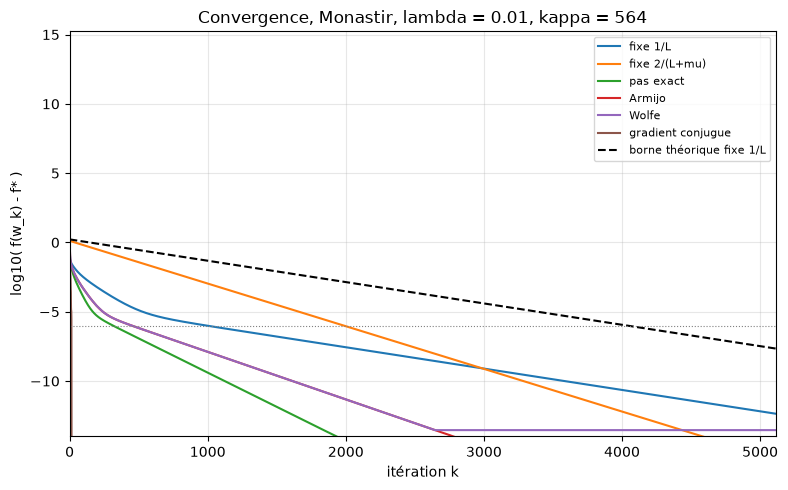

In [8]:
fig, ax = plt.subplots(figsize=(8, 5))
k_axis = np.arange(len(study["fixe 1/L"]["hist"]))
for m in ["fixe 1/L", "fixe 2/(L+mu)", "pas exact", "Armijo", "Wolfe", "gradient conjugue"]:
    h = study[m]["hist"]
    ax.plot(np.arange(len(h)), np.log10(np.maximum(h, 1e-300)), label=m)
rho_1L = 1 - 1 / prob["kappa"]
theory = np.log10(np.maximum(rho_1L ** (2 * k_axis) * study["fixe 1/L"]["hist"][0], 1e-300))
ax.plot(k_axis, theory, "k--", label="borne théorique fixe 1/L")
ax.axhline(math.log10(RATIO_TARGET), color="grey", lw=0.8, ls=":")
ax.set_xlabel("itération k")
ax.set_ylabel("log10( f(w_k) - f* )")
ax.set_title(f"Convergence, {REF_SITE}, lambda = {LAM}, kappa = {prob['kappa']:.3g}")
ax.set_xlim(0, min(len(k_axis), int(pred["fixe_1/L"] * 1.3) + 50))
ax.set_ylim(-14, None)
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 7. Diagnostic du conditionnement et reconditionnement

Diagnostic : quelles directions propres portent $\kappa$ ? Reformulation testée :
(a) préconditionnement diagonal $M = \mathrm{diag}(H)$ de la descente (le problème ne change pas) ;
(b) retrait des retards corrélés (change le modèle : on mesure aussi l'erreur de test).

In [9]:
corr = pd.DataFrame(ds["A_tr"][:, :-1], columns=ds["names"][:-1]).corr()
pairs = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
             .stack().sort_values(key=np.abs, ascending=False).head(6))
print("Corrélations les plus fortes entre colonnes standardisées :")
print(pairs.round(3).to_string())

vals, vecs = np.linalg.eigh(prob["H"])
top = np.argsort(-np.abs(vecs[:, -1]))[:4]
print("\nDirection propre associée à L (composantes dominantes) :")
for j in top:
    print(f"  {ds['names'][j]:>14s} : {vecs[j, -1]: .3f}")

# (a) préconditionnement diagonal
Mdiag = np.diag(prob["H"]).copy()
Mhalf = 1 / np.sqrt(Mdiag)
Hp = prob["H"] * np.outer(Mhalf, Mhalf)
eig_p = np.linalg.eigvalsh(Hp)
kappa_p = eig_p[-1] / eig_p[0]
print(f"\n(a) kappa avant = {prob['kappa']:.4g} ; après préconditionnement diagonal = {kappa_p:.4g} "
      f"(gain x{prob['kappa']/kappa_p:.3f})")
print(f"    diagonale de H : min {Mdiag.min():.4f}, max {Mdiag.max():.4f}")

# pas 1/L_p : L_p, mu_p = extrêmes de la valeur propre de M^-1 H (réelles, positives)
eig_MH = np.sort(np.linalg.eigvals(prob["H"] / Mdiag[:, None]).real)
mu_p, Lp = float(eig_MH[0]), float(eig_MH[-1])
prob_p = dict(prob, L=Lp, mu=mu_p)
kp_pred = math.log(1 / RATIO_TARGET) / (-2 * math.log(1 - mu_p / Lp))
prec = descend("fixe 1/L", prob_p, np.zeros(prob["d"]), STUDY_ITER, stop_on_grad=False, precond=Mdiag)
print(f"    prédiction (préconditionné, pas 1/L_p) : {math.ceil(kp_pred)} itérations ; "
      f"observé : {iters_to_ratio(prec['hist'])}")

# (b) retrait des retards corrélés
keep = [i for i, nm in enumerate(ds["names"]) if nm not in ("ALLSKY_lag1", "ALLSKY_lag2")]
prob_b = make_problem(ds["A_tr"][:, keep], ds["y_tr"], LAM)
print(f"\n(b) retrait de ALLSKY_lag1 et lag2 : kappa = {prob_b['kappa']:.4g} "
      f"(gain x{prob['kappa']/prob_b['kappa']:.2f})")
pred_b = predicted_iterations(prob_b["kappa"])
print(f"    itérations prédites pour 1/L : {math.ceil(pred_b['fixe_1/L'])}")

Corrélations les plus fortes entre colonnes standardisées :
T2M          T2M_MIN    0.987
             T2M_MAX    0.984
T2M_MAX      T2M_MIN    0.947
ALLSKY_lag2  cos_doy   -0.877
ALLSKY_lag1  cos_doy   -0.875
ALLSKY_lag0  cos_doy   -0.874

Direction propre associée à L (composantes dominantes) :
         T2M_MAX : -0.369
             T2M : -0.365
         cos_doy :  0.357
         T2M_MIN : -0.347

(a) kappa avant = 564.3 ; après préconditionnement diagonal = 564.3 (gain x1.000)
    diagonale de H : min 1.0100, max 1.0100


    prédiction (préconditionné, pas 1/L_p) : 3895 itérations ; observé : 858

(b) retrait de ALLSKY_lag1 et lag2 : kappa = 449.3 (gain x1.26)
    itérations prédites pour 1/L : 3100


## 8. Ridge : comparaison avec scikit-learn et erreurs de prévision

`sklearn.linear_model.Ridge` minimise $\|y - Xw\|^2 + \alpha\|w\|^2$. Multiplier $f$ par $2n$ donne
$\|Aw-y\|^2 + n\lambda\|w\|^2$ : il faut donc `alpha = n * lambda` **et** `fit_intercept=False`,
car la colonne de 1 est déjà dans $A$. Sans ces réglages, la solution change par simple paramétrage.

In [10]:
from sklearn.linear_model import Ridge

A_tr, y_tr, A_te, y_te = ds["A_tr"], ds["y_tr"], ds["A_te"], ds["y_te"]
w_gd = official["fixe 1/L"]["w"]
w_cg = conjugate_gradient(prob, np.zeros(prob["d"]), STUDY_ITER, stop_on_grad=False)["w"]

sk = Ridge(alpha=prob["n"] * LAM, fit_intercept=False, solver="cholesky").fit(A_tr, y_tr)
sk_naive = Ridge(alpha=LAM, fit_intercept=True).fit(A_tr[:, :-1], y_tr)   # mauvais réglage, à titre d'exemple

def f_at(w):
    return prob["f"](w)

print("Équivalence avec sklearn (alpha = n*lambda, fit_intercept=False) :")
print(f"  max |w_sklearn - w*| = {np.max(np.abs(sk.coef_ - prob['w_star'])):.2e}")
print(f"  max |w_GD - w*|      = {np.max(np.abs(w_gd - prob['w_star'])):.2e}")
print(f"  max |w_CG - w*|      = {np.max(np.abs(w_cg - prob['w_star'])):.2e}")
print(f"  f(w_sklearn) - f*    = {f_at(sk.coef_) - prob['f_star']:.2e}")
print(f"  mauvais réglage (alpha = lambda, intercept libre) : max |w - w*| = "
      f"{np.max(np.abs(np.append(sk_naive.coef_, sk_naive.intercept_)[:-1] - prob['w_star'][:-1])):.3f}")

def mae(a, b):
    return float(np.mean(np.abs(a - b)))

def rmse(a, b):
    return float(np.sqrt(np.mean((a - b) ** 2)))

y_hat = A_te @ prob["w_star"] + ds["mu_y"]          # on rajoute le centrage
y_sk = A_te @ sk.coef_ + ds["mu_y"]
naive = ds["naive_te"]
score = pd.DataFrame({
    "modele": ["ridge (w*)", "ridge (sklearn)", "naive (demain = aujourd'hui)"],
    "MAE": [mae(y_hat, ds["y_te"]), mae(y_sk, ds["y_te"]), mae(naive, ds["y_te"])],
    "RMSE": [rmse(y_hat, ds["y_te"]), rmse(y_sk, ds["y_te"]), rmse(naive, ds["y_te"])],
})
print(f"\nTest : {ds['n_test']} jours (cibles du {ds['first_test_target']} au dernier jour disponible)")
print(score.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

Équivalence avec sklearn (alpha = n*lambda, fit_intercept=False) :
  max |w_sklearn - w*| = 6.00e-15
  max |w_GD - w*|      = 2.56e-02
  max |w_CG - w*|      = 2.37e-14
  f(w_sklearn) - f*    = 0.00e+00
  mauvais réglage (alpha = lambda, intercept libre) : max |w - w*| = 0.453

Test : 912 jours (cibles du 2024-01-01 au dernier jour disponible)
                      modele    MAE   RMSE
                  ridge (w*) 0.6689 0.9386
             ridge (sklearn) 0.6689 0.9386
naive (demain = aujourd'hui) 0.7874 1.2044


## 9. Résultats par site (format commun, axe 1)

Les mêmes méthodes sont appliquées à chaque site : mêmes variables, même $\lambda$, même procédure.
Colonnes reprises du format commun : `kappa`, `iter_pred` (pas $1/L$), `iter_obs` (pas $1/L$), `rmse_ridge`, `rmse_naif`.

In [11]:
def site_summary(name, lat, lon):
    df, _ = load_site(name, lat, lon)
    d = build_dataset(df)
    p = make_problem(d["A_tr"], d["y_tr"], LAM)
    pr = predicted_iterations(p["kappa"])
    run = descend("fixe 1/L", p, np.zeros(p["d"]), STUDY_ITER, stop_on_grad=False)
    w = p["w_star"]
    yh = d["A_te"] @ w + d["mu_y"]
    return {
        "site": name, "lat": lat, "lon": lon,
        "n_app": d["n_train"], "n_test": d["n_test"],
        "kappa": round(p["kappa"], 2),
        "iter_pred": math.ceil(pr["fixe_1/L"]),
        "iter_obs": iters_to_ratio(run["hist"]),
        "rmse_ridge": round(rmse(yh, d["y_te"]), 4),
        "rmse_naif": round(rmse(d["naive_te"], d["y_te"]), 4),
        "mae_ridge": round(mae(yh, d["y_te"]), 4),
        "mae_naif": round(mae(d["naive_te"], d["y_te"]), 4),
    }

results_axe1 = pd.DataFrame([site_summary(n_, *c_) for n_, c_ in SITES.items()])
print(results_axe1.to_string(index=False))

       site   lat    lon  n_app  n_test  kappa  iter_pred  iter_obs  rmse_ridge  rmse_naif  mae_ridge  mae_naif
   Monastir 35.78  10.83   3649     912 564.32       3895       858      0.9386     1.2044     0.6689    0.7874
Tamanrasset 22.79   5.52   3649     912 461.87       3188       703      0.7090     0.8027     0.4832    0.5210
      Dakar 14.69 -17.44   3649     912 398.32       2749      1319      0.7897     0.9514     0.5369    0.6095


## 10. Lecture des résultats (valeurs de l'exécution du site de référence)

- **H1 partiellement infirmée** : $\kappa \approx 564$ confirme le mauvais conditionnement, mais la descente à pas $1/L$
  atteint $10^{-6}$ en environ 860 itérations, contre 3 900 prédites. La prédiction est une borne au pire cas ;
  l'écart signifie que la direction de plus faible courbure pèse peu dans l'erreur initiale $w_0 = 0$.
  Cette explication n'a pas été vérifiée numériquement. Le pas $2/(L+\mu)$ est en revanche proche de la prédiction
  (environ 1 900 contre 1 950).
- **Gradient conjugué** : de l'ordre de 14 itérations contre 91 prédites, environ 60 fois moins que le pas $1/L$.
- **H2 confirmée** : la diagonale de $H$ est constante (1,01) car les variables sont standardisées ;
  le préconditionnement diagonal ne gagne rien.
- **Conditionnement** : la direction de $L$ mélange températures (T2M, T2M_MAX, T2M_MIN) et cosinus saisonnier.
  Retirer deux retards corrélés ramène $\kappa$ de 564 à 449, mais change le modèle.
- **Équivalence sklearn** : écart de $6 \cdot 10^{-15}$ sur les coefficients, comme attendu de la formule $\alpha = n\lambda$.
- **Prévision** : le ridge bat la prévision naïve (RMSE 0,94 contre 1,20 kWh/m²/jour sur Monastir).
  Le constat est le même sur les trois sites.

Note sur le critère d'arrêt : l'arrêt $\|\nabla f\|^2 \le 10^{-6}$ laisse un écart de l'ordre de $10^{-5}$ à $10^{-4}$ par rapport à $w^\star$
(colonne `log10_ecart_final_officiel`). Les mesures de vitesse, elles, n'utilisent pas cet arrêt.

## 11. Export du résumé (axe 1) et limites

Le notebook ne produit pas le CSV commun complet (axes 2 à 4 absents). Les colonnes de l'axe 1 sont exportées
dans `axe1_resume.csv`. Limites : une seule taille de fenêtre (3 jours de rayonnement) ; un seul $\lambda$ étudié
en détail ; la prédiction spectrale est une borne au pire cas ; la comparaison des sites n'a pas encore été
associée au classement de difficulté (D.1 à D.3).

In [12]:
results_axe1.to_csv("axe1_resume.csv", index=False)
print("Écrit : axe1_resume.csv")

Écrit : axe1_resume.csv
